# Лабораторная 2. Классическая обработка изображений

Задание целиком: `labs/lab02/README.md` в репозитории курса.

Ноутбук один на обе части:
- **Часть 1** (после лекции 2): освещённость и шум по всем фото, гистограммы, коррекция яркости, сравнение фильтров;
- **Часть 2** (после лекции 3): выделение животного на фото, проверка маски по разметке, признаки формы.

Как работать:
1. В первой ячейке впишите свой номер варианта.
2. Заполняйте ячейки с пометкой `TODO` сверху вниз. Ячейки без `TODO` уже готовы, их менять не нужно.
3. Пока вы не дошли до части 2, её ячейки можно не трогать: Run All проходит через них без ошибок.
4. В конце выполните Run All с нуля, скачайте ноутбук и `results.zip`.

В Kaggle включите интернет: Settings → Internet → On.

## 0. Установка и загрузка данных

Ячейка определяет, где запущен ноутбук, находит или скачивает `get_data.py` из репозитория курса и загружает ваш вариант. Ничего в ней менять не нужно, кроме `VARIANT`.

In [1]:
VARIANT = 5   # TODO: ваш порядковый номер в списке группы, например 7
DATA_SOURCE = None  # запасной путь: папка с архивами variant_NN.zip

import os
import sys
import inspect
import urllib.request
from pathlib import Path

assert isinstance(VARIANT, int) and 0 <= VARIANT <= 22, "Впишите свой номер варианта: целое число от 1 до 22"
if VARIANT == 0:
    print("ВНИМАНИЕ: вариант 00 демонстрационный, работа на нём не засчитывается")

if "google.colab" in sys.modules:
    ENV, DATA_ROOT = "colab", Path("/content/data")
elif Path("/kaggle/working").exists():
    ENV, DATA_ROOT = "kaggle", Path("/kaggle/working/data")
elif Path("../../data/get_data.py").exists():
    # Ноутбук открыт прямо из клона репозитория курса: данные кладём в его папку data/
    ENV, DATA_ROOT = "local", Path("../../data").resolve()
else:
    # Локально: ноутбук лежит в cv-2026-familiya/lab02/, данные кладём в cv-2026-familiya/data/.
    # Эта папка указана в .gitignore, в репозиторий она не попадёт.
    ENV, DATA_ROOT = "local", Path("..").resolve() / "data"
DATA_ROOT.mkdir(parents=True, exist_ok=True)
print("среда:", ENV, "| папка данных:", DATA_ROOT)

GET_DATA_URL = "https://raw.githubusercontent.com/ykvnkm/computer-vision-course/main/data/get_data.py"
course_copy = Path("../../data/get_data.py")
kaggle_copies = sorted(Path("/kaggle/input").glob("**/get_data.py")) if ENV == "kaggle" else []
if course_copy.exists():
    script_dir = course_copy.resolve().parent
elif kaggle_copies:
    # Kaggle с подключённым датасетом-зеркалом курса: интернет не нужен
    script_dir = kaggle_copies[0].parent
    print("get_data.py из подключённого датасета:", kaggle_copies[0])
else:
    script_dir = DATA_ROOT
    if not (script_dir / "get_data.py").exists():
        try:
            urllib.request.urlretrieve(GET_DATA_URL, script_dir / "get_data.py")
        except Exception as e:
            raise RuntimeError("Не удалось скачать get_data.py. В Kaggle включите Internet в Settings; "
                               "в остальных случаях проверьте подключение к сети.") from e
sys.path.insert(0, str(script_dir))
from get_data import ensure_variant

params = inspect.signature(ensure_variant).parameters
kwargs = {"dest": DATA_ROOT} if "dest" in params else {}
if DATA_SOURCE and "source" in params:
    kwargs["source"] = DATA_SOURCE
DATA_DIR = Path(ensure_variant(VARIANT, **kwargs))
print("данные варианта:", DATA_DIR)
print(sorted(p.name for p in DATA_DIR.iterdir()))

среда: colab | папка данных: /content/data
Вариант 05: British_Shorthair, Russian_Blue, saint_bernard, shiba_inu
  Скачиваю https://github.com/ykvnkm/computer-vision-course/releases/download/data-v1/variant_05.zip
  variant_05.zip: 88.4 МБ, готово.                              
  Распаковываю в /content/data/variant_05 ...
Готово: /content/data/variant_05 (805 изображений)
данные варианта: /content/data/variant_05
['.get_data.json', 'README.md', 'annotations', 'images', 'labels.csv', 'variant.json']


In [2]:
import time

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from PIL import Image
from skimage.restoration import estimate_sigma
from skimage.metrics import structural_similarity

IMG_DIR = DATA_DIR / "images"
TRIMAP_DIR = DATA_DIR / "annotations" / "trimaps"
RESULTS = Path("results")
RESULTS.mkdir(exist_ok=True)

labels = pd.read_csv(DATA_DIR / "labels.csv")
print(len(labels), "фото,", labels["breed"].nunique(), "породы:", ", ".join(labels["breed"].unique()))
print("OpenCV", cv2.__version__, "| numpy", np.__version__, "| pandas", pd.__version__)

805 фото, 4 породы: British_Shorthair, Russian_Blue, saint_bernard, shiba_inu
OpenCV 4.14.0 | numpy 2.1.3 | pandas 2.2.3


### Общие функции

Готовый код, менять не нужно.

- `load_rgb(filename)` читает фото через Pillow с `.convert("RGB")` (в датасете есть файлы в режимах `L`, `RGBA`, `P`, это вы видели в лабе 1) и уменьшает его так, чтобы длинная сторона стала 512 px. Одинаковый масштаб нужен, чтобы ядро 5×5 действовало на всех фото одинаково.
- `load_trimap(filename, shape)` читает trimap и приводит его к размеру фото через `cv2.INTER_NEAREST`: значения 1, 2, 3 не смешиваются.
- `show_grid(images, titles, ncols, path)` рисует картинки сеткой и, если указан `path`, сохраняет PNG.

In [3]:
MAX_SIDE = 512   # длинная сторона после уменьшения, px


def load_rgb(filename):
    """Фото как RGB uint8, длинная сторона MAX_SIDE."""
    with Image.open(IMG_DIR / filename) as im:
        rgb = np.asarray(im.convert("RGB"))
    h, w = rgb.shape[:2]
    scale = MAX_SIDE / max(h, w)
    size = (round(w * scale), round(h * scale))           # cv2.resize ждёт (ширина, высота)
    interp = cv2.INTER_AREA if scale < 1 else cv2.INTER_LINEAR
    return cv2.resize(rgb, size, interpolation=interp)


def load_trimap(filename, shape):
    """Trimap того же размера, что фото: 1 = животное, 2 = фон, 3 = граница."""
    with Image.open(TRIMAP_DIR / (Path(filename).stem + ".png")) as im:
        tri = np.asarray(im)
    return cv2.resize(tri, (shape[1], shape[0]), interpolation=cv2.INTER_NEAREST)


def show_grid(images, titles=None, ncols=4, path=None, size=3.0):
    """Картинки сеткой: RGB как есть, 2D-массивы в оттенках серого. path: куда сохранить PNG."""
    nrows = (len(images) + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(size * ncols, size * nrows), squeeze=False)
    for ax in axes.ravel():
        ax.axis("off")
    for i, img in enumerate(images):
        ax = axes.ravel()[i]
        img = np.asarray(img)
        if img.dtype == bool:
            img = img.astype(np.uint8)
        if img.ndim == 2:
            ax.imshow(img, cmap="gray", vmin=0, vmax=1 if img.max() <= 1 else 255)
        else:
            ax.imshow(img)
        if titles is not None:
            ax.set_title(titles[i], fontsize=9)
    plt.tight_layout()
    if path is not None:
        plt.savefig(path, dpi=100)
    plt.show()


example = load_rgb(labels["filename"].iloc[0])
print(labels["filename"].iloc[0], example.shape, example.dtype)

British_Shorthair_2.jpg (512, 460, 3) uint8


# Часть 1. Освещённость, шум, фильтры

Делается после лекции 2. Результат части: четыре числа по каждому фото, гистограммы, сравнение способов поправить тёмные фото и сравнение фильтров на зашумлённых фото. Из этой части дальше понадобится одна переменная `BEST_FILTER`.

## 1.1 Четыре числа по каждому фото

| Число | Что показывает | Как считать |
|---|---|---|
| `mean_L` | средняя яркость | среднее канала L из `cv2.COLOR_RGB2LAB` (в 8-битном OpenCV L идёт от 0 до 255) |
| `std_L` | контраст | стандартное отклонение того же канала |
| `noise_sigma` | оценка шума в единицах яркости | `estimate_sigma(gray)` из `skimage.restoration` |
| `sharpness` | резкость: у размытого кадра мало перепадов | дисперсия `cv2.Laplacian(gray, cv2.CV_64F)` |

Допишите функцию `image_stats`. Следующая ячейка готова: она пройдёт по всем фото и сохранит `results/part1_stats.csv`.

In [4]:
def image_stats(rgb):
    """Словарь {"mean_L", "std_L", "noise_sigma", "sharpness"} для одного кадра."""
    lab = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB)
    L = lab[..., 0]
    mean_L = float(L.mean())
    std_L = float(L.std())
    gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
    noise_sigma = float(estimate_sigma(gray))
    sharpness = float(cv2.Laplacian(gray, cv2.CV_64F).var())

    return {"mean_L": mean_L,
        "std_L": std_L,
        "noise_sigma": noise_sigma,
        "sharpness": sharpness}

In [5]:
rows = []
for r in labels.itertuples():
    with Image.open(IMG_DIR / r.filename) as im:
        width, height = im.size                      # исходный размер файла
    rows.append({"filename": r.filename, "breed": r.breed, "species": r.species,
                 "width": width, "height": height, **image_stats(load_rgb(r.filename))})
stats = pd.DataFrame(rows)
stats.to_csv(RESULTS / "part1_stats.csv", index=False, float_format="%.4f")
stats.describe().round(2)

,width,height,mean_L,std_L,noise_sigma,sharpness
count,805.00,805.00,805.00,805.00,805.00,805.00
mean,447.51,397.64,125.75,57.15,1.53,651.95
std,84.40,83.95,32.64,13.48,1.29,789.46
min,194.00,196.00,36.86,18.43,0.00,9.20
25%,375.00,333.00,105.01,48.54,0.73,201.22
50%,500.00,375.00,125.84,57.69,1.15,389.30
75%,500.00,500.00,143.80,67.22,1.86,813.92
max,1200.00,900.00,238.09,94.27,9.62,7892.49


In [6]:
breed_stats = stats.groupby("breed")[
    ["mean_L", "std_L", "noise_sigma", "sharpness"]
].mean().round(2)

breed_stats
print("Самая тёмная порода:", breed_stats["mean_L"].idxmin())
print("Наименьшая резкость:", breed_stats["sharpness"].idxmin())

Самая тёмная порода: shiba_inu
Наименьшая резкость: British_Shorthair


## 1.2 Гистограммы

Нужен один рисунок `results/histograms.png`: распределение `mean_L` по всем фото и гистограммы каналов R, G, B самого тёмного и самого светлого фото. Рядом с гистограммами удобно показать сами фото.

Самое тёмное фото: shiba_inu_137.jpg
Самое светлое фото: saint_bernard_183.jpg


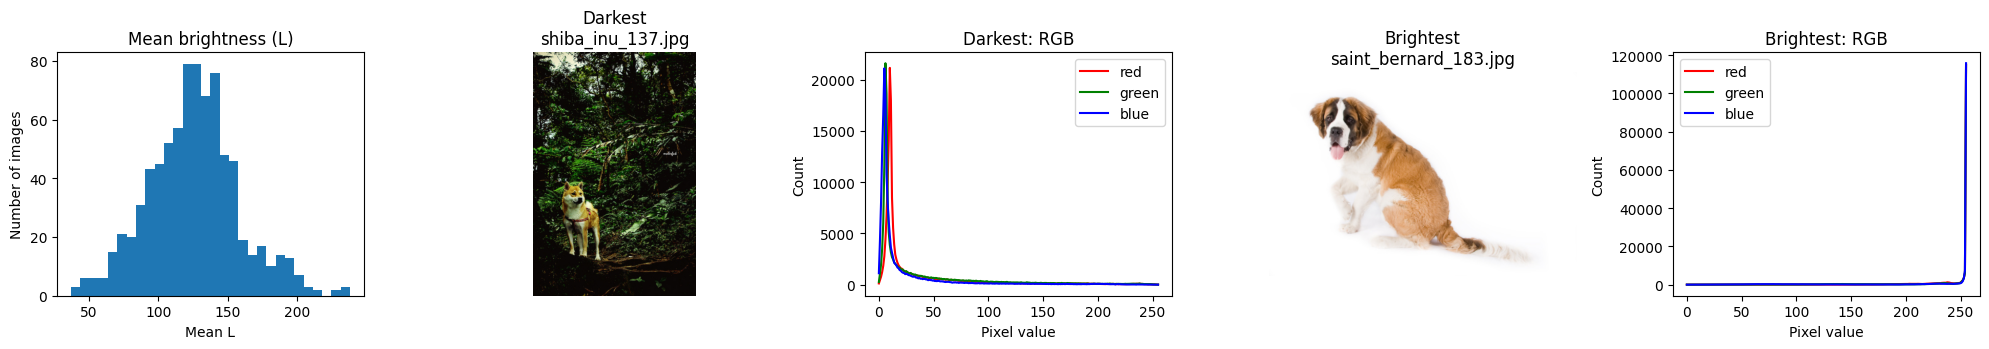

In [7]:
darkest_name = stats.loc[stats["mean_L"].idxmin(), "filename"]
brightest_name = stats.loc[stats["mean_L"].idxmax(), "filename"]

print("Самое тёмное фото:", darkest_name)
print("Самое светлое фото:", brightest_name)

darkest_rgb = load_rgb(darkest_name)
brightest_rgb = load_rgb(brightest_name)

fig, axes = plt.subplots(1, 5, figsize=(20, 3.6))

axes[0].hist(stats["mean_L"], bins=30)
axes[0].set_title("Mean brightness (L)")
axes[0].set_xlabel("Mean L")
axes[0].set_ylabel("Number of images")

axes[1].imshow(darkest_rgb)
axes[1].set_title(f"Darkest\n{darkest_name}")
axes[1].axis("off")

for c, color in enumerate(["red", "green", "blue"]):
    hist = np.bincount(darkest_rgb[..., c].ravel(), minlength=256)
    axes[2].plot(hist, color=color, label=color)
axes[2].set_title("Darkest: RGB")
axes[2].set_xlabel("Pixel value")
axes[2].set_ylabel("Count")
axes[2].legend()

axes[3].imshow(brightest_rgb)
axes[3].set_title(f"Brightest\n{brightest_name}")
axes[3].axis("off")

for c, color in enumerate(["red", "green", "blue"]):
    hist = np.bincount(brightest_rgb[..., c].ravel(), minlength=256)
    axes[4].plot(hist, color=color, label=color)
axes[4].set_title("Brightest: RGB")
axes[4].set_xlabel("Pixel value")
axes[4].set_ylabel("Count")
axes[4].legend()

plt.tight_layout()
plt.savefig(RESULTS / "histograms.png", dpi=100)
plt.show()

## 1.3 Освещённость

Возьмите 5 самых тёмных фото и сравните четыре способа их поправить:

| Метод | Что делает |
|---|---|
| `eq_rgb` | `cv2.equalizeHist` по каждому каналу R, G, B отдельно |
| `eq_L` | `cv2.equalizeHist` только по каналу L в Lab, каналы a и b не трогаем |
| `clahe_L` | CLAHE по каналу L: `cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))` |
| `gamma` | гамма-коррекция `255 * (x / 255) ** γ`; при γ < 1 тёмные места светлеют сильнее светлых |

Для каждого фото и метода нужны `mean_L` и `std_L` после коррекции и сдвиг цвета: насколько изменились каналы a и b в Lab. Функция `color_shift` готова.

In [8]:
def color_shift(before, after):
    """Средний сдвиг цвета |Δa| + |Δb| в Lab между двумя RGB-кадрами. 0 = оттенки не изменились."""
    lab0 = cv2.cvtColor(before, cv2.COLOR_RGB2LAB).astype(np.float32)
    lab1 = cv2.cvtColor(after, cv2.COLOR_RGB2LAB).astype(np.float32)
    return float(np.abs(lab1[..., 1:] - lab0[..., 1:]).sum(axis=2).mean())

In [9]:
GAMMA = 0.5

def correct(rgb, method):
    """method: "eq_rgb", "eq_L", "clahe_L" или "gamma". Возвращает RGB uint8 того же размера."""

    if method == "eq_rgb":
        r, g, b = cv2.split(rgb)

        r = cv2.equalizeHist(r)
        g = cv2.equalizeHist(g)
        b = cv2.equalizeHist(b)

        return cv2.merge([r, g, b])

    elif method == "eq_L" or method == "clahe_L":
        lab = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB)
        L, a, b = cv2.split(lab)

        if method == "eq_L":
            L = cv2.equalizeHist(L)

        elif method == "clahe_L":
            clahe = cv2.createCLAHE(
                clipLimit=2.0,
                tileGridSize=(8, 8)
            )
            L = clahe.apply(L)

        lab = cv2.merge([L, a, b])
        return cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)

    elif method == "gamma":
        lut = np.array([
            255 * (i / 255) ** GAMMA
            for i in range(256)
        ], dtype=np.uint8)

        return cv2.LUT(rgb, lut)

    else:
        raise ValueError(f"Неизвестный метод коррекции: {method}")

,mean_L,std_L,color_shift
method,,,
clahe_L,63.99,58.94,0.28
eq_L,114.05,75.81,0.65
eq_rgb,120.85,74.34,23.91
gamma,89.78,55.18,8.21
original,42.47,45.92,0.00


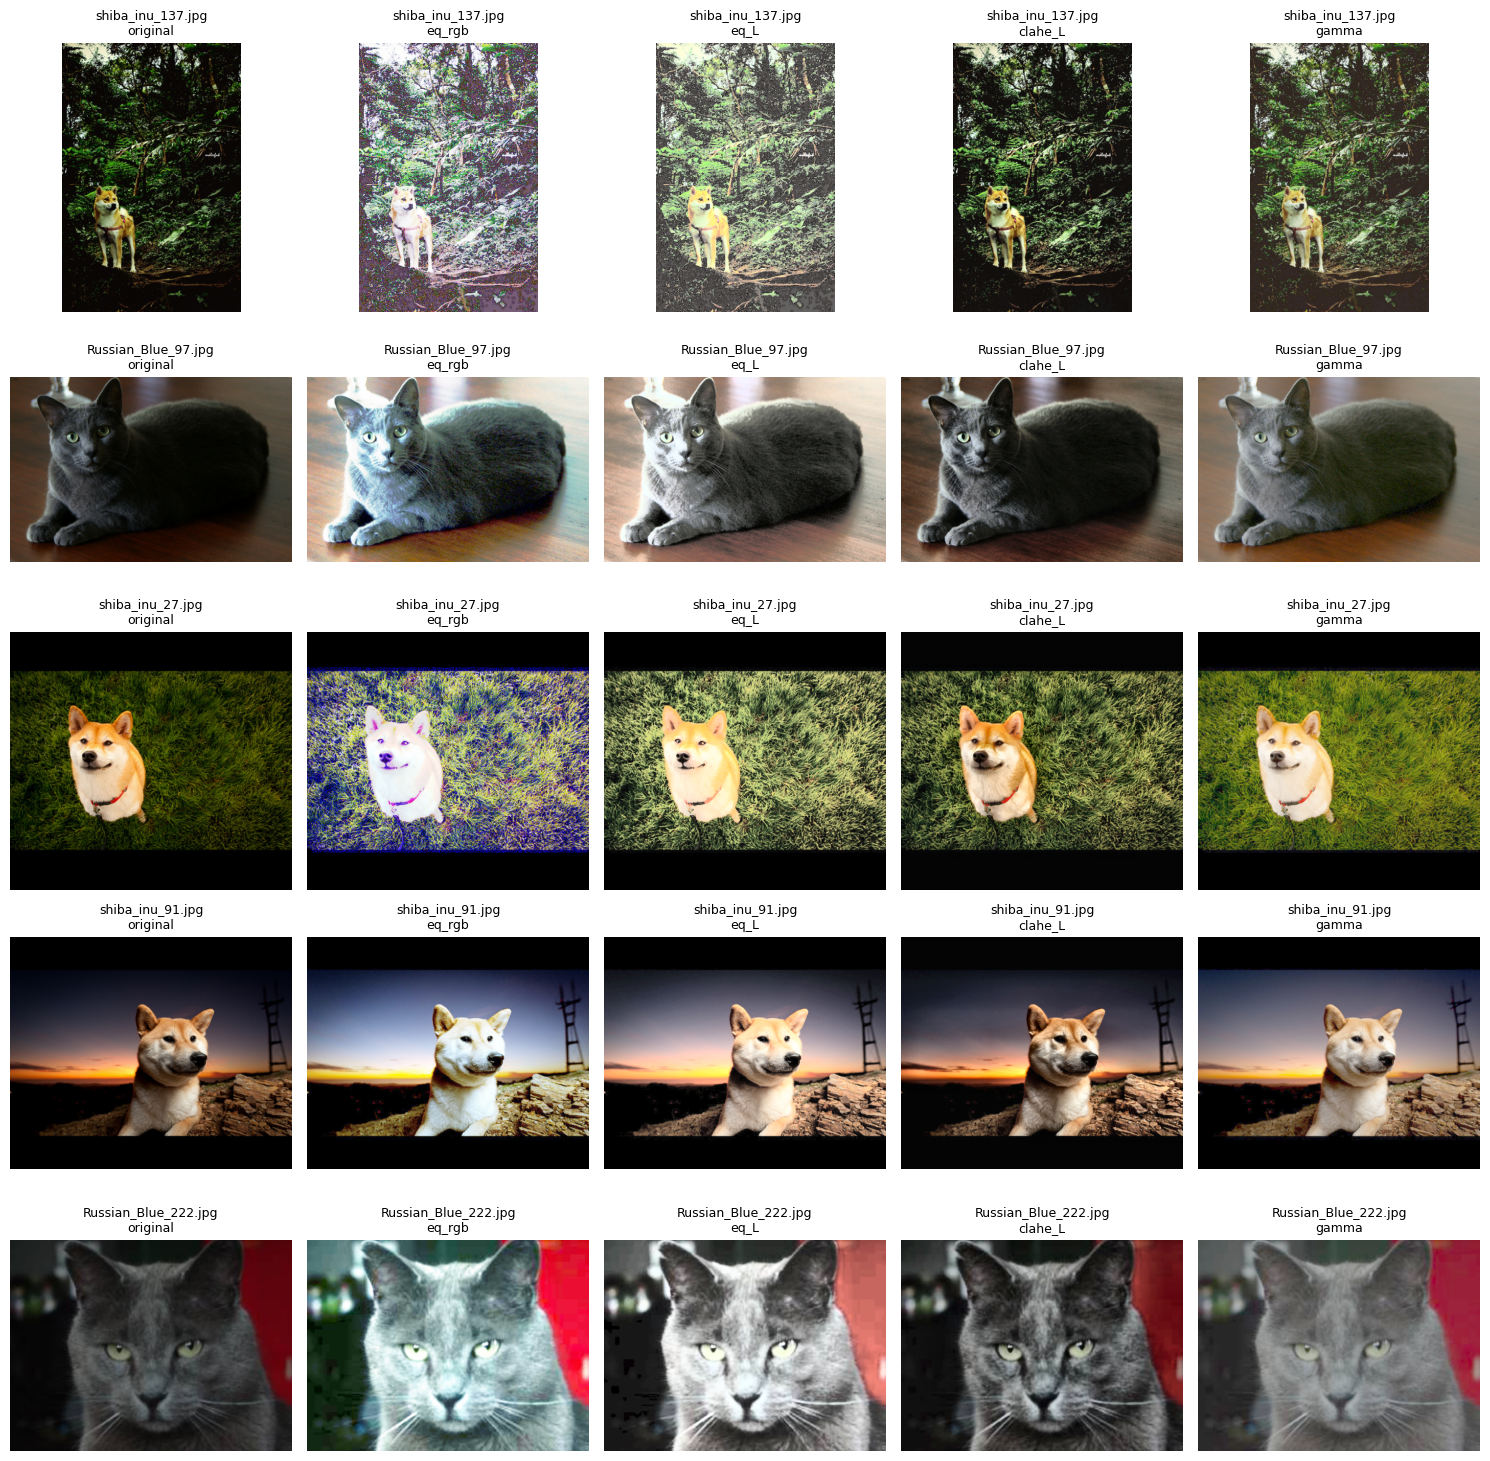

In [10]:
METHODS = ["eq_rgb", "eq_L", "clahe_L", "gamma"]

darkest = stats.nsmallest(5, "mean_L")

rows = []

for r in darkest.itertuples():
    rgb = load_rgb(r.filename)

    original_stats = image_stats(rgb)
    rows.append({
        "filename": r.filename,
        "method": "original",
        "mean_L": original_stats["mean_L"],
        "std_L": original_stats["std_L"],
        "color_shift": 0.0
    })

    for method in METHODS:
        corrected = correct(rgb, method)
        corrected_stats = image_stats(corrected)

        rows.append({
            "filename": r.filename,
            "method": method,
            "mean_L": corrected_stats["mean_L"],
            "std_L": corrected_stats["std_L"],
            "color_shift": color_shift(rgb, corrected)
        })

illum = pd.DataFrame(rows)

display(
    illum.groupby("method")[
        ["mean_L", "std_L", "color_shift"]
    ].mean().round(2)
)

grid_images = []
titles = []

for r in darkest.itertuples():
    rgb = load_rgb(r.filename)
    grid_images.append(rgb)
    titles.append(f"{r.filename}\noriginal")

    for method in METHODS:
        corrected = correct(rgb, method)
        grid_images.append(corrected)
        titles.append(f"{r.filename}\n{method}")

show_grid(
    grid_images,
    titles,
    ncols=5,
    path=RESULTS / "illumination.png"
)

## 1.4 Свёртка руками

`cv2.blur(img, (3, 3))` усредняет каждый пиксель с восемью соседями. То же самое делает свёртка `cv2.filter2D` с ядром 3×3, в котором все девять чисел равны 1/9. Проверьте это на любом фото.

Максимум модуля разницы: 0


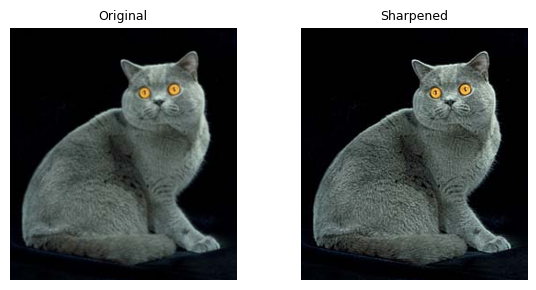

In [11]:
img = load_rgb(labels["filename"].iloc[0])

kernel = np.ones((3, 3), np.float32) / 9

filtered_2d = cv2.filter2D(img, -1, kernel)
blurred = cv2.blur(img, (3, 3))

diff = np.abs(
    filtered_2d.astype(np.int16) - blurred.astype(np.int16)
)

print("Максимум модуля разницы:", diff.max())

sharpen_kernel = np.array([
    [0, -1, 0],
    [-1, 5, -1],
    [0, -1, 0]
], dtype=np.float32)

sharpened = cv2.filter2D(img, -1, sharpen_kernel)

show_grid(
    [img, sharpened],
    ["Original", "Sharpened"],
    ncols=2
)

## 1.5 Шум и фильтры

У каждого варианта свой шум, он задан в `NOISE_PLAN`:

- `gauss`: к каждому пикселю добавлено случайное число из нормального распределения со стандартным отклонением `sigma` (в единицах яркости 0..255);
- `sp` («соль и перец»): доля `amount` пикселей стала чисто чёрной или чисто белой;
- `mix`: оба шума сразу.

Шум добавляется к 30 случайным фото варианта. Фильтр получает зашумлённое фото, результат сравнивается с исходным:

- PSNR в децибелах (`cv2.PSNR`): чем больше, тем ближе к исходному;
- SSIM от 0 до 1 (`structural_similarity`): похожесть по локальной структуре, ближе к тому, что видит глаз;
- время на кадр в миллисекундах.

Сравните `cv2.blur`, `cv2.GaussianBlur`, `cv2.medianBlur` с ядрами 3, 5, 7 и `cv2.bilateralFilter`. По желанию добавьте `cv2.fastNlMeansDenoisingColored`.

In [12]:
NOISE_PLAN = {
    0: {"kind": "gauss", "sigma": 20},
    1: {"kind": "sp", "amount": 0.05},
    2: {"kind": "mix", "sigma": 15, "amount": 0.03},
    3: {"kind": "gauss", "sigma": 30},
    4: {"kind": "sp", "amount": 0.10},
    5: {"kind": "mix", "sigma": 20, "amount": 0.05},
    6: {"kind": "gauss", "sigma": 10},
    7: {"kind": "sp", "amount": 0.02},
    8: {"kind": "mix", "sigma": 10, "amount": 0.02},
    9: {"kind": "gauss", "sigma": 25},
    10: {"kind": "sp", "amount": 0.08},
    11: {"kind": "mix", "sigma": 15, "amount": 0.05},
    12: {"kind": "gauss", "sigma": 15},
    13: {"kind": "sp", "amount": 0.04},
    14: {"kind": "mix", "sigma": 20, "amount": 0.03},
    15: {"kind": "gauss", "sigma": 30},
    16: {"kind": "sp", "amount": 0.06},
    17: {"kind": "mix", "sigma": 10, "amount": 0.04},
    18: {"kind": "gauss", "sigma": 20},
    19: {"kind": "sp", "amount": 0.03},
    20: {"kind": "mix", "sigma": 25, "amount": 0.05},
    21: {"kind": "gauss", "sigma": 25},
    22: {"kind": "sp", "amount": 0.10},
}


def add_noise(rgb, kind, sigma=0, amount=0.0, seed=0):
    """Зашумлённая копия RGB-кадра. kind: "gauss", "sp" или "mix"."""
    rng = np.random.default_rng(seed)
    out = rgb.astype(np.float32)
    if kind in ("gauss", "mix"):
        out = out + rng.normal(0, sigma, out.shape)
    out = np.clip(out, 0, 255).astype(np.uint8)
    if kind in ("sp", "mix"):
        r = rng.random(out.shape[:2])
        out[r < amount / 2] = 0
        out[r > 1 - amount / 2] = 255
    return out

шум варианта: kind=mix sigma=20 amount=0.05


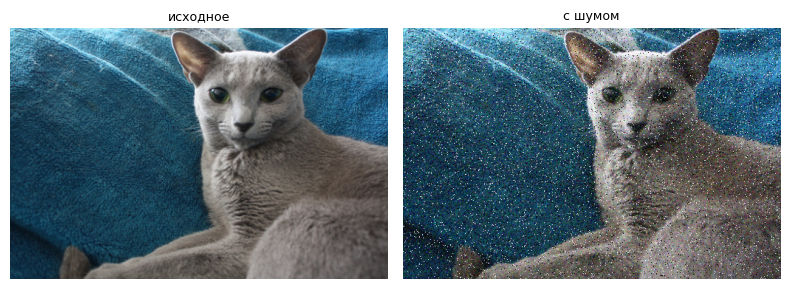

In [13]:
NOISE = NOISE_PLAN[VARIANT]
NOISE_NAME = " ".join(f"{k}={v}" for k, v in NOISE.items())
sample = labels.sample(30, random_state=VARIANT)
clean = [load_rgb(fn) for fn in sample["filename"]]
noisy = [add_noise(img, seed=VARIANT * 100 + i, **NOISE) for i, img in enumerate(clean)]
print("шум варианта:", NOISE_NAME)
show_grid([clean[0], noisy[0]], ["исходное", "с шумом"], ncols=2, size=4)

In [14]:
FILTERS = {
    "blur3": lambda img: cv2.blur(img, (3, 3)),
    "blur5": lambda img: cv2.blur(img, (5, 5)),
    "blur7": lambda img: cv2.blur(img, (7, 7)),
    "gaussian3": lambda img: cv2.GaussianBlur(img, (3, 3), 0),
    "gaussian5": lambda img: cv2.GaussianBlur(img, (5, 5), 0),
    "gaussian7": lambda img: cv2.GaussianBlur(img, (7, 7), 0),
    "median3": lambda img: cv2.medianBlur(img, 3),
    "median5": lambda img: cv2.medianBlur(img, 5),
    "median7": lambda img: cv2.medianBlur(img, 7),
    "bilateral": lambda img: cv2.bilateralFilter(img, 9, 75, 75)
}

In [15]:
def quality(clean_img, out_img):
    """Насколько результат фильтра похож на чистый кадр: {"psnr": ..., "ssim": ...}."""
    psnr = float(cv2.PSNR(clean_img, out_img))
    ssim = float(structural_similarity(
        clean_img,
        out_img,
        channel_axis=2,
        data_range=255
    ))
    return {"psnr": psnr, "ssim": ssim}

In [16]:
# Готовый цикл: каждый фильтр на 30 фото, время и качество. "none" = зашумлённое фото без фильтра.
rows = []
for name, f in {"none": lambda img: img, **FILTERS}.items():
    for fn, c, n in zip(sample["filename"], clean, noisy):
        t0 = time.perf_counter()
        out = f(n)
        ms = (time.perf_counter() - t0) * 1000
        rows.append({"filter": name, "filename": fn, "ms": ms, **quality(c, out)})
filt = pd.DataFrame(rows)
filt_summary = filt.groupby("filter").mean(numeric_only=True).round(4)
filt_summary.insert(0, "noise", NOISE_NAME)
filt_summary.to_csv(RESULTS / "filters.csv")
filt_summary

,noise,ms,psnr,ssim
filter,,,,
bilateral,kind=mix sigma=20 amount=0.05,37.8187,17.7667,0.3067
blur3,kind=mix sigma=20 amount=0.05,0.3863,24.6376,0.5134
blur5,kind=mix sigma=20 amount=0.05,0.5159,26.0759,0.6148
blur7,kind=mix sigma=20 amount=0.05,0.6132,26.0501,0.6464
gaussian3,kind=mix sigma=20 amount=0.05,0.7672,24.1357,0.4952
gaussian5,kind=mix sigma=20 amount=0.05,0.7394,25.6740,0.5816
gaussian7,kind=mix sigma=20 amount=0.05,1.4421,26.4608,0.6475
median3,kind=mix sigma=20 amount=0.05,0.3300,27.6620,0.6386
median5,kind=mix sigma=20 amount=0.05,1.7236,28.5242,0.7095


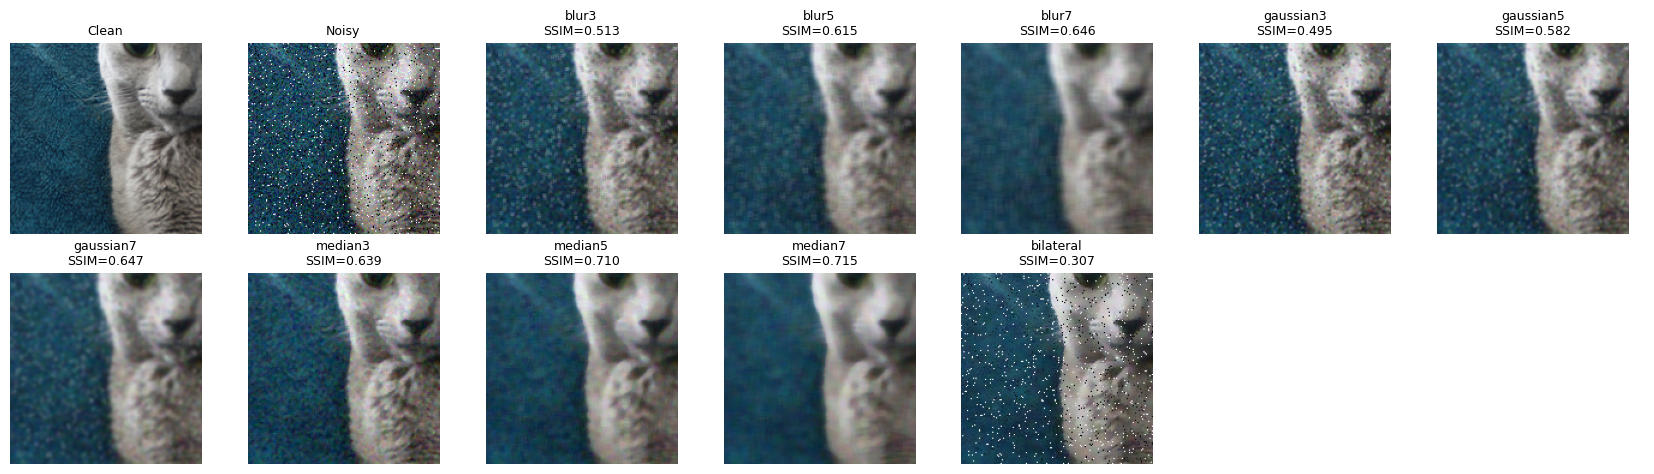

In [17]:
crop_size = 160
h, w = clean[0].shape[:2]
y1 = (h - crop_size) // 2
x1 = (w - crop_size) // 2

clean_crop = clean[0][y1:y1 + crop_size, x1:x1 + crop_size]
noisy_crop = noisy[0][y1:y1 + crop_size, x1:x1 + crop_size]

crops = [clean_crop, noisy_crop]
titles = ["Clean", "Noisy"]

for name, filter_fn in FILTERS.items():
    filtered = filter_fn(noisy[0])
    filtered_crop = filtered[y1:y1 + crop_size, x1:x1 + crop_size]

    ssim_value = filt_summary.loc[name, "ssim"]

    crops.append(filtered_crop)
    titles.append(f"{name}\nSSIM={ssim_value:.3f}")

show_grid(
    crops,
    titles,
    ncols=7,
    path=RESULTS / "filters.png",
    size=2.4
)

In [18]:
filt_summary.sort_values("ssim", ascending=False)

BEST_FILTER = filt_summary.sort_values(
    "ssim", ascending=False
).index[0]

print("Лучший фильтр:", BEST_FILTER)

Лучший фильтр: median7


По PSNR лучший результат показал `median5`, а по SSIM — `median7`, что указывает на различие между точностью восстановления пикселей и сохранением структурного сходства изображения. Однако `median7` работает значительно медленнее, поэтому `median5` представляет более практичный компромисс между качеством и вычислительными затратами. При сравнении также важно учитывать обработку кропов: время выполнения зависит от размера обрабатываемых областей, поэтому результаты следует оценивать при одинаковых условиях.

# Часть 2 (после лекции 3). Выделение животного и признаки формы

Эту часть делайте после лекции 3. Кто хочет, может сделать её сразу: все функции и подсказки ниже.

Задача: получить маску животного без нейросети. Пайплайн: канал → порог Оцу → полярность → морфология → заливка дыр → самая большая связная компонента → контур и признаки формы. Качество маски проверяем по trimap через IoU, пиксели границы (значение 3) не учитываем.

Из части 1 сюда приходит только `BEST_FILTER`.

In [19]:
def iou_ignore(pred, trimap):
    """IoU маски pred с животным из trimap; пиксели границы (значение 3) не учитываются."""
    valid = trimap != 3
    gt = trimap == 1
    pred = np.asarray(pred) > 0
    inter = np.logical_and(pred, gt)[valid].sum()
    union = np.logical_or(pred, gt)[valid].sum()
    return float(inter / union) if union else float("nan")


def overlay(rgb, mask, color=(0, 255, 0), alpha=0.45):
    """Фото с маской, закрашенной полупрозрачным цветом."""
    out = rgb.copy()
    m = np.asarray(mask) > 0
    out[m] = ((1 - alpha) * out[m] + alpha * np.array(color)).astype(np.uint8)
    return out


# Каналы, из которых можно выбирать. Можно добавить свои.
CHANNELS = {
    "gray": lambda rgb: cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY),
    "S": lambda rgb: cv2.split(cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV))[1],
    "V": lambda rgb: cv2.split(cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV))[2],
    "L": lambda rgb: cv2.split(cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB))[0],
    "a": lambda rgb: cv2.split(cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB))[1],
    "b": lambda rgb: cv2.split(cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB))[2],
}

## 2.1 Один кадр по шагам

Пройдите пайплайн на одном фото и сохраните `results/pipeline.png`: исходное фото, trimap, серое, Оцу, после исправления полярности, после морфологии, после заливки и выбора компоненты, контур на фото, адаптивный порог для сравнения. В подписях укажите IoU масок.

Каждый шаг удобно сразу оформить функцией: в 2.2 из них соберётся `segment`.

In [20]:
EXAMPLE = labels["filename"].sample(1, random_state=VARIANT).iloc[0]   # можно заменить на любое фото варианта
rgb = load_rgb(EXAMPLE)
tri = load_trimap(EXAMPLE, rgb.shape)
print(EXAMPLE, rgb.shape, "значения trimap:", np.unique(tri))

Russian_Blue_14.jpg (341, 512, 3) значения trimap: [1 2 3]


Порог Оцу: 101.0


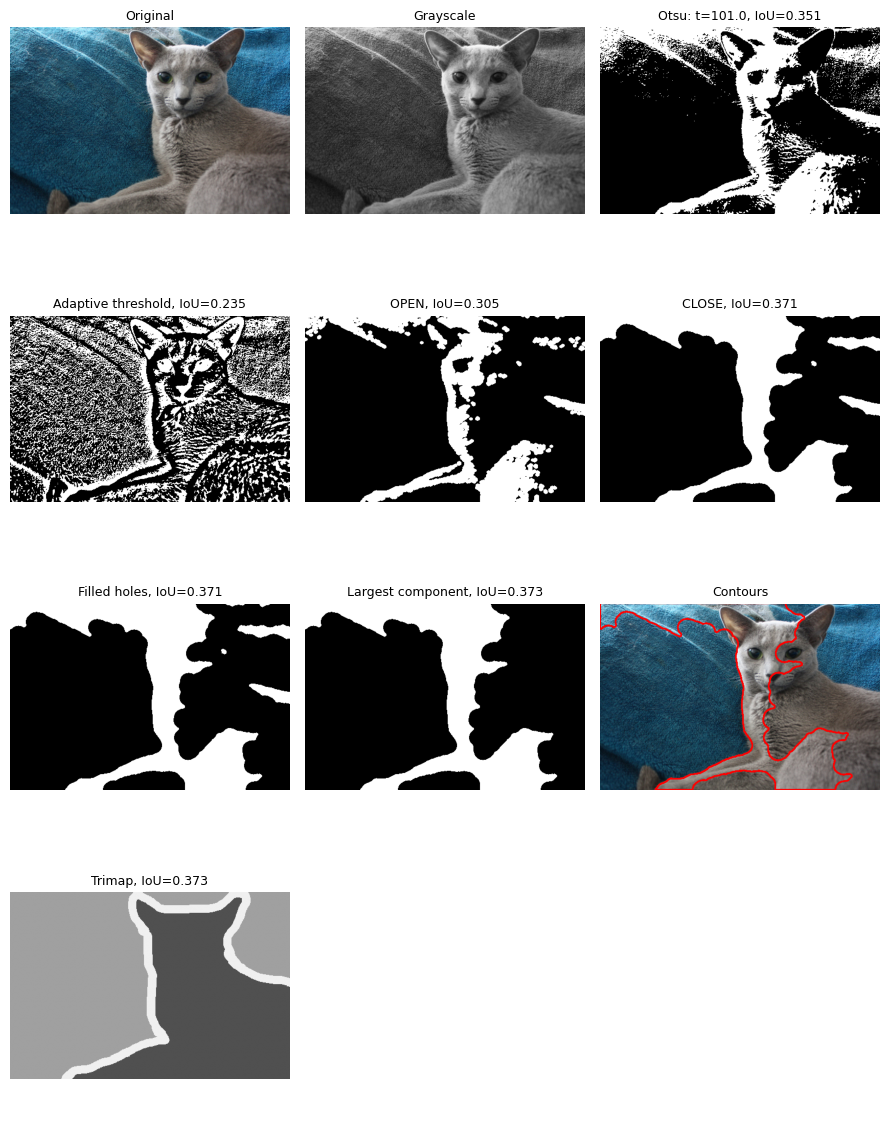

In [21]:

rgb = load_rgb(EXAMPLE)
gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)

t, mask = cv2.threshold(
    gray, 0, 255,
    cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

print("Порог Оцу:", t)

border = np.concatenate([
    mask[:10, :].ravel(),
    mask[-10:, :].ravel(),
    mask[:, :10].ravel(),
    mask[:, -10:].ravel()
])

if np.mean(border == 255) > 0.5:
    mask = cv2.bitwise_not(mask)

adaptive = cv2.adaptiveThreshold(
    gray, 255,
    cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv2.THRESH_BINARY,
    51, 5
)

if np.mean(np.concatenate([
    adaptive[:10, :].ravel(),
    adaptive[-10:, :].ravel(),
    adaptive[:, :10].ravel(),
    adaptive[:, -10:].ravel()
]) == 255) > 0.5:
    adaptive = cv2.bitwise_not(adaptive)

kernel_7 = cv2.getStructuringElement(
    cv2.MORPH_ELLIPSE, (7, 7)
)

opened = cv2.morphologyEx(
    mask, cv2.MORPH_OPEN, kernel_7
)

kernel_31 = cv2.getStructuringElement(
    cv2.MORPH_ELLIPSE, (31, 31)
)

closed = cv2.morphologyEx(
    opened, cv2.MORPH_CLOSE, kernel_31
)

padded = cv2.copyMakeBorder(
    closed, 1, 1, 1, 1,
    cv2.BORDER_CONSTANT,
    value=0
)

flood = padded.copy()
flood_mask = np.zeros(
    (flood.shape[0] + 2, flood.shape[1] + 2),
    np.uint8
)

cv2.floodFill(flood, flood_mask, (0, 0), 255)

filled = cv2.bitwise_not(flood)[1:-1, 1:-1] | closed

num_labels, labels_cc, stats_cc, centroids = (
    cv2.connectedComponentsWithStats(filled, connectivity=8)
)

if num_labels > 1:
    largest_label = 1 + np.argmax(
        stats_cc[1:, cv2.CC_STAT_AREA]
    )
    largest = np.uint8(labels_cc == largest_label) * 255
else:
    largest = filled.copy()

contours, _ = cv2.findContours(
    largest.copy(),
    cv2.RETR_EXTERNAL,
    cv2.CHAIN_APPROX_NONE
)

contour_img = rgb.copy()
cv2.drawContours(
    contour_img, contours, -1, (255, 0, 0), 2
)

tri = np.asarray(tri)
trimap_vis = tri * 80

images = [
    rgb,
    gray,
    mask,
    adaptive,
    opened,
    closed,
    filled,
    largest,
    contour_img,
    trimap_vis
]

titles = [
    "Original",
    "Grayscale",
    f"Otsu: t={t}, IoU={iou_ignore(mask, tri):.3f}",
    f"Adaptive threshold, IoU={iou_ignore(adaptive, tri):.3f}",
    f"OPEN, IoU={iou_ignore(opened, tri):.3f}",
    f"CLOSE, IoU={iou_ignore(closed, tri):.3f}",
    f"Filled holes, IoU={iou_ignore(filled, tri):.3f}",
    f"Largest component, IoU={iou_ignore(largest, tri):.3f}",
    "Contours",
    f"Trimap, IoU={iou_ignore(largest, tri):.3f}"
]

show_grid(
    images,
    titles,
    ncols=3,
    path=RESULTS / "pipeline.png",
    size=3
)


## 2.2 Функция `segment` и выбор канала

`segment` повторяет шаги 2.1 для любого фото. Флаги включают шаги по одному: так в 2.3 будет видно, что даёт каждый. Пока функция не написана, она возвращает пустую маску, и ячейки ниже работают с IoU = 0.

Канал не обязан быть серым: животное может отличаться от фона насыщенностью (`S`) или цветом (`a`, `b`). Сравните минимум два канала из `CHANNELS` готовой функцией `evaluate` и выберите `CHANNEL`. Каждый вызов `evaluate` проходит по всем фото варианта и занимает 10–30 секунд.

In [22]:
def segment(rgb, channel="gray", smooth=True, polarity=True, morph=True, fill=True, k_open=7, k_close=31):
    if smooth and BEST_FILTER is not None:
        rgb = FILTERS[BEST_FILTER](rgb)

    x = CHANNELS[channel](rgb)

    _, mask = cv2.threshold(
        x, 0, 255,
        cv2.THRESH_BINARY + cv2.THRESH_OTSU
    )

    if polarity:
        border = np.concatenate([
            mask[:10, :].ravel(),
            mask[-10:, :].ravel(),
            mask[:, :10].ravel(),
            mask[:, -10:].ravel()
        ])

        if np.mean(border == 255) > 0.5:
            mask = cv2.bitwise_not(mask)

    if morph:
        kernel_open = cv2.getStructuringElement(
            cv2.MORPH_ELLIPSE, (k_open, k_open)
        )
        kernel_close = cv2.getStructuringElement(
            cv2.MORPH_ELLIPSE, (k_close, k_close)
        )

        mask = cv2.morphologyEx(
            mask, cv2.MORPH_OPEN, kernel_open
        )
        mask = cv2.morphologyEx(
            mask, cv2.MORPH_CLOSE, kernel_close
        )

    if fill:
        padded = cv2.copyMakeBorder(
            mask, 1, 1, 1, 1,
            cv2.BORDER_CONSTANT, value=0
        )

        flood = padded.copy()
        flood_mask = np.zeros(
            (flood.shape[0] + 2, flood.shape[1] + 2),
            np.uint8
        )

        cv2.floodFill(flood, flood_mask, (0, 0), 255)

        mask = cv2.bitwise_not(flood)[1:-1, 1:-1] | mask

        num_labels, labels_cc, stats_cc, _ = (
            cv2.connectedComponentsWithStats(
                mask, connectivity=8
            )
        )

        if num_labels > 1:
            largest_label = 1 + np.argmax(
                stats_cc[1:, cv2.CC_STAT_AREA]
            )
            mask = np.uint8(labels_cc == largest_label) * 255

    return mask > 0

In [23]:
def evaluate(configs):
    """configs: {имя: параметры segment}. Прогоняет segment на всех фото варианта.
    Возвращает таблицу IoU: строка = фото, столбец = имя набора параметров."""
    rows = []
    for fn in labels["filename"]:
        rgb = load_rgb(fn)
        tri = load_trimap(fn, rgb.shape)
        rows.append({"filename": fn, **{name: iou_ignore(segment(rgb, **kw), tri) for name, kw in configs.items()}})
    return pd.DataFrame(rows).set_index("filename")


def summarize(table):
    """Средняя и медианная IoU по каждому столбцу таблицы из evaluate."""
    return pd.DataFrame({"mean_iou": table.mean(), "median_iou": table.median()}).round(3)

In [24]:
ch = evaluate({
    "gray": dict(channel="gray"),
    "S": dict(channel="S")
})

display(summarize(ch))

k_results = evaluate({
    "k_close=15": dict(channel="gray", k_close=15),
    "k_close=31": dict(channel="gray", k_close=31),
    "k_close=45": dict(channel="gray", k_close=45)
})

display(summarize(k_results))


,mean_iou,median_iou
gray,0.436,0.421
S,0.374,0.336


,mean_iou,median_iou
k_close=15,0.413,0.388
k_close=31,0.436,0.421
k_close=45,0.451,0.430


## 2.3 Что даёт каждый шаг

Готовая ячейка: шаги включаются по одному на выбранном канале, результат сохраняется в `results/ablation.csv`.

In [25]:
CHANNEL = "gray"
ABLATION = {
    "1 только Оцу": dict(channel=CHANNEL, smooth=False, polarity=False, morph=False, fill=False),
    "2 + фильтр из части 1": dict(channel=CHANNEL, smooth=True, polarity=False, morph=False, fill=False),
    "3 + полярность": dict(channel=CHANNEL, smooth=True, polarity=True, morph=False, fill=False),
    "4 + морфология": dict(channel=CHANNEL, smooth=True, polarity=True, morph=True, fill=False),
    "5 + заливка и компонента": dict(channel=CHANNEL, smooth=True, polarity=True, morph=True, fill=True),
}
FINAL = ABLATION["5 + заливка и компонента"]

abl = evaluate(ABLATION)
abl_summary = summarize(abl)
abl_summary.to_csv(RESULTS / "ablation.csv", index_label="step")
print("канал:", CHANNEL, "| фильтр:", BEST_FILTER)
abl_summary

канал: gray | фильтр: median7


,mean_iou,median_iou
1 только Оцу,0.227,0.166
2 + фильтр из части 1,0.231,0.165
3 + полярность,0.384,0.349
4 + морфология,0.411,0.384
5 + заливка и компонента,0.436,0.421


## 2.4 Признаки формы

Для итоговой маски каждого фото нужны признаки самого большого внешнего контура:

| Признак | Как считать |
|---|---|
| `area_frac` | `cv2.contourArea(c)` / площадь кадра |
| `perimeter` | `cv2.arcLength(c, True)` |
| `x, y, w, h` | `cv2.boundingRect(c)` |
| `elongation` | длинная сторона / короткая сторона `cv2.minAreaRect(c)[1]` |
| `circularity` | 4π × площадь / периметр²; у круга 1, у вытянутой и рваной фигуры меньше |
| `solidity` | площадь / площадь `cv2.convexHull(c)`; лапы и хвост её уменьшают |

Допишите `shape_features`. Следующая ячейка готова: она соберёт `results/masks.csv` (строка на фото: IoU и признаки).

In [26]:
def shape_features(mask):
    mask = mask.astype(np.uint8)

    contours, _ = cv2.findContours(
        mask,
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_NONE
    )

    if not contours:
        return {}

    contour = max(contours, key=cv2.contourArea)

    area = cv2.contourArea(contour)
    perimeter = cv2.arcLength(contour, True)

    x, y, w, h = cv2.boundingRect(contour)

    image_area = mask.shape[0] * mask.shape[1]
    area_frac = area / image_area if image_area > 0 else 0

    elongation = max(w, h) / min(w, h) if min(w, h) > 0 else 0

    circularity = (
        4 * np.pi * area / (perimeter ** 2)
        if perimeter > 0 else 0
    )

    hull = cv2.convexHull(contour)
    hull_area = cv2.contourArea(hull)

    solidity = area / hull_area if hull_area > 0 else 0

    return {
        "area_frac": area_frac,
        "perimeter": perimeter,
        "x": x,
        "y": y,
        "w": w,
        "h": h,
        "elongation": elongation,
        "circularity": circularity,
        "solidity": solidity
    }

In [27]:
rows = []
for r in labels.itertuples():
    rgb = load_rgb(r.filename)
    mask = segment(rgb, **FINAL)
    rows.append({"filename": r.filename, "breed": r.breed, "species": r.species,
                 "iou": iou_ignore(mask, load_trimap(r.filename, rgb.shape)), **shape_features(mask)})
masks = pd.DataFrame(rows)
masks.to_csv(RESULTS / "masks.csv", index=False, float_format="%.4f")
masks.head()

,filename,breed,species,iou,area_frac,perimeter,x,y,w,h,elongation,circularity,solidity
0,British_Shorthair_2.jpg,British_Shorthair,cat,0.996051,0.454855,1614.888514,24,46,402,432,1.074627,0.516209,0.842184
1,British_Shorthair_3.jpg,British_Shorthair,cat,0.000855,0.094676,1195.303604,0,281,512,54,9.481481,0.155616,0.709238
2,British_Shorthair_6.jpg,British_Shorthair,cat,0.955331,0.221795,1064.028561,114,42,266,284,1.067669,0.460063,0.820967
3,British_Shorthair_8.jpg,British_Shorthair,cat,0.533526,0.231056,1707.072279,23,62,319,343,1.075235,0.186713,0.588112
4,British_Shorthair_9.jpg,British_Shorthair,cat,0.829324,0.361739,1280.430582,106,64,341,321,1.062305,0.546542,0.866721


In [28]:
breed_summary = masks.groupby("breed")[
    ["iou", "area_frac", "elongation", "circularity", "solidity"]
].mean().round(3)

display(breed_summary)

print(
    "Хуже всего метод работает на породе:",
    breed_summary["iou"].idxmin()
)

species_summary = masks.groupby("species")[
    ["iou", "area_frac", "elongation", "circularity", "solidity"]
].mean().round(3)

display(species_summary)

,iou,area_frac,elongation,circularity,solidity
breed,,,,,
British_Shorthair,0.473,0.447,1.462,0.319,0.723
Russian_Blue,0.483,0.444,1.424,0.308,0.712
saint_bernard,0.406,0.366,1.499,0.272,0.694
shiba_inu,0.384,0.417,1.447,0.289,0.701


Хуже всего метод работает на породе: shiba_inu


,iou,area_frac,elongation,circularity,solidity
species,,,,,
cat,0.478,0.445,1.443,0.314,0.718
dog,0.395,0.392,1.473,0.281,0.698


## 2.5 Лучшие и худшие маски

Галерея из 6 лучших и 6 худших масок по IoU сохраняется в `results/best_worst.png`. Посмотрите на худшие: что у них общего (фон того же цвета, что животное, тёмный кадр, ошибка в самой разметке)?

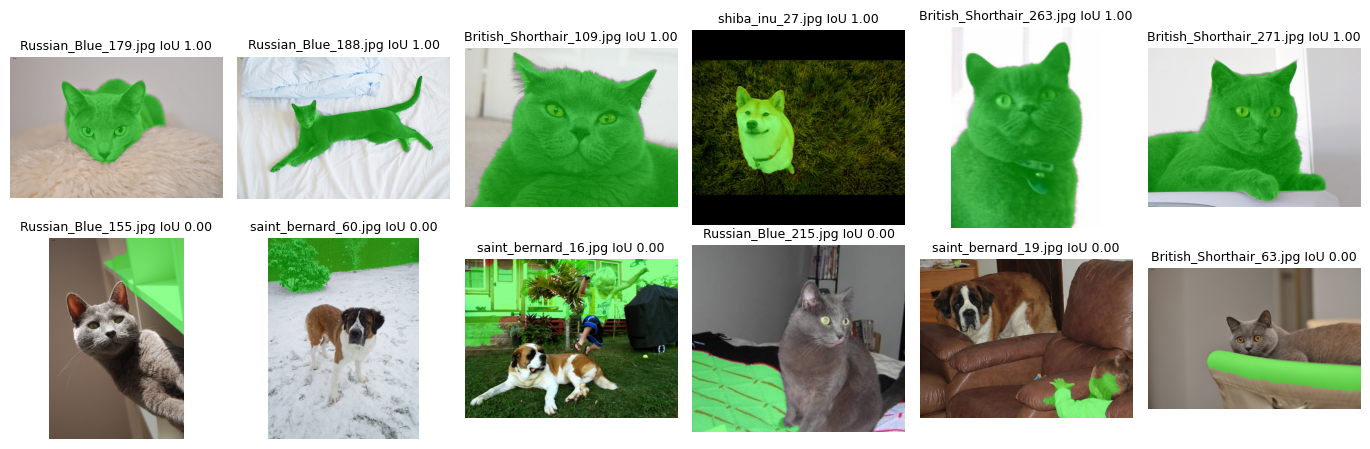

In [29]:
ranked = masks.dropna(subset=["iou"]).sort_values(
    "iou", ascending=False
)

selected = pd.concat([
    ranked.head(6),
    ranked.tail(6)
])

panels = []
titles = []

for r in selected.itertuples():
    rgb = load_rgb(r.filename)
    mask = segment(rgb, **FINAL)
    result = overlay(rgb, mask)

    panels.append(result)
    titles.append(f"{r.filename} IoU {r.iou:.2f}")

show_grid(
    panels,
    titles,
    ncols=6,
    path=RESULTS / "best_worst.png",
    size=2.3
)

## Выгрузка

Ячейка ниже проверяет, что все 9 файлов на месте, и печатает главное для отчёта. Затем упакуйте `results/` в архив и скачайте:
- в Kaggle: правая панель → Output → `results.zip` → Download; ноутбук: File → Download Notebook;
- в Colab: архив скачается сам после запуска ячейки; ноутбук: File → Download → Download .ipynb;
- локально: ничего скачивать не нужно, всё уже лежит в папке `lab02/`.

Переименуйте скачанный ноутбук в `solution.ipynb`.

In [30]:
print(f"вариант {VARIANT} | шум {NOISE_NAME} | BEST_FILTER = {BEST_FILTER} | CHANNEL = {CHANNEL}")

expected = {"part1_stats.csv", "histograms.png", "illumination.png", "filters.csv", "filters.png",
            "pipeline.png", "ablation.csv", "masks.csv", "best_worst.png"}
missing = sorted(expected - {p.name for p in RESULTS.iterdir()})
print("не хватает:", ", ".join(missing) if missing else "ничего, все 9 файлов на месте")

вариант 5 | шум kind=mix sigma=20 amount=0.05 | BEST_FILTER = median7 | CHANNEL = gray
не хватает: ничего, все 9 файлов на месте


In [31]:
import shutil
if ENV != "local":
    archive = shutil.make_archive("results", "zip", RESULTS)
    print("архив:", archive)
    if ENV == "colab":
        from google.colab import files
        files.download(archive)

архив: /content/results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>